# Aula 6.11 — Desafio: investigando a redução de dimensionalidade

**Dataset Wine** (`load_wine()`): 178 vinhos de 3 cultivares, descritos por 13 características químicas.

Objetivo: reduzir as 13 dimensões para 2 com PCA implementado em NumPy, conferir com o scikit-learn e investigar o efeito da padronização.

O rótulo do cultivar (`y`) **não participa do PCA**: ele serve só para colorir os gráficos.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA          # só nas comparações (etapas 10 e 11)
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=4, suppress=True)

## Etapa 1 — Carregar o dataset

In [2]:
wine = load_wine()
X = wine.data.astype(float)
y = wine.target
nomes = wine.feature_names
cultivares = ["cultivar 0", "cultivar 1", "cultivar 2"]

print("X:", X.shape, "| y:", y.shape)
print("Vinhos por cultivar:", np.bincount(y))

X: (178, 13) | y: (178,)
Vinhos por cultivar: [59 71 48]


## Etapa 2 — Explorar as características

Repare na **escala** de cada coluna: `proline` passa de 1 000, enquanto `hue` fica perto de 1. Isso vai fazer diferença no PCA.

In [3]:
print(f"{'característica':<30}{'média':>10}{'desvio':>10}{'mínimo':>10}{'máximo':>10}")
for j, nome in enumerate(nomes):
    col = X[:, j]
    print(f"{nome:<30}{col.mean():>10.2f}{col.std():>10.2f}{col.min():>10.2f}{col.max():>10.2f}")

característica                     média    desvio    mínimo    máximo
alcohol                            13.00      0.81     11.03     14.83
malic_acid                          2.34      1.11      0.74      5.80
ash                                 2.37      0.27      1.36      3.23
alcalinity_of_ash                  19.49      3.33     10.60     30.00
magnesium                          99.74     14.24     70.00    162.00
total_phenols                       2.30      0.62      0.98      3.88
flavanoids                          2.03      1.00      0.34      5.08
nonflavanoid_phenols                0.36      0.12      0.13      0.66
proanthocyanins                     1.59      0.57      0.41      3.58
color_intensity                     5.06      2.31      1.28     13.00
hue                                 0.96      0.23      0.48      1.71
od280/od315_of_diluted_wines        2.61      0.71      1.27      4.00
proline                           746.89    314.02    278.00   1680.00


## Etapa 3 — Centralizar os dados

In [4]:
media = X.mean(axis=0)
X_c = X - media
print("Médias depois de centralizar (devem ser ~0):", X_c.mean(axis=0).round(10))
assert np.allclose(X_c.mean(axis=0), 0)

Médias depois de centralizar (devem ser ~0): [ 0.  0. -0.  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]


## Etapa 4 — Matriz de covariância

`C = Xcᵀ Xc / (n − 1)`: com 13 características, a matriz é **13 × 13**.

In [5]:
n = X.shape[0]
cov = X_c.T @ X_c / (n - 1)
print("Formato:", cov.shape)
print("Igual a np.cov?", np.allclose(cov, np.cov(X_c, rowvar=False)))
print("Variância de cada característica (diagonal):")
for nome, v in sorted(zip(nomes, np.diag(cov)), key=lambda t: -t[1])[:4]:
    print(f"   {nome:<30}{v:>14.2f}")

Formato: (13, 13)
Igual a np.cov? True
Variância de cada característica (diagonal):
   proline                             99166.72
   magnesium                             203.99
   alcalinity_of_ash                      11.15
   color_intensity                         5.37


## Etapa 5 — Autovalores e autovetores

`np.linalg.eigh` (a covariância é simétrica), depois ordenamos do maior para o menor autovalor.

In [6]:
autovalores, autovetores = np.linalg.eigh(cov)
ordem = np.argsort(autovalores)[::-1]
autovalores = autovalores[ordem]
autovetores = autovetores[:, ordem]
print("Autovalores (maior → menor):")
print(autovalores.round(4))

Autovalores (maior → menor):
[99201.7895   172.5353     9.4381     4.9912     1.2288     0.8411
     0.279      0.1514     0.1121     0.0717     0.0376     0.0211
     0.0082]


## Etapa 6 — Variância explicada (EVR)

PC1:  99.81%  | acumulada  99.81%
PC2:   0.17%  | acumulada  99.98%
PC3:   0.01%  | acumulada  99.99%
PC4:   0.01%  | acumulada 100.00%


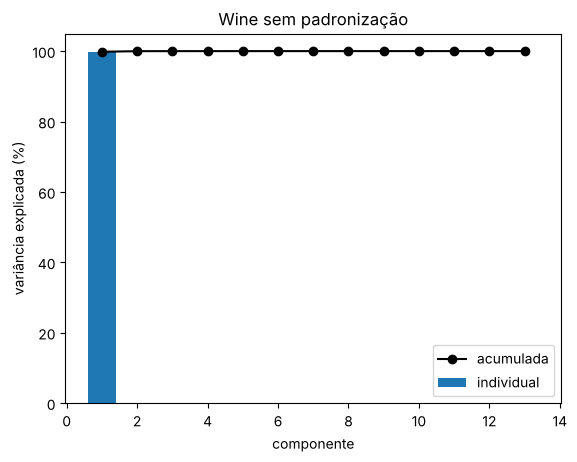

In [7]:
evr = autovalores / autovalores.sum()
acumulada = np.cumsum(evr)
for i in range(4):
    print(f"PC{i+1}: {evr[i]*100:6.2f}%  | acumulada {acumulada[i]*100:6.2f}%")

plt.bar(range(1, 14), evr * 100, label="individual")
plt.plot(range(1, 14), acumulada * 100, "ko-", label="acumulada")
plt.xlabel("componente"); plt.ylabel("variância explicada (%)")
plt.title("Wine sem padronização"); plt.legend(); plt.show()

## Etapa 7 — Selecionar dois componentes

`W` é a matriz de projeção 13 × 2, com os dois primeiros autovetores. Olhar os **pesos** mostra o que cada componente "mede".

In [8]:
W = autovetores[:, :2]
assert np.allclose(W.T @ W, np.eye(2))          # colunas ortonormais

for pc in range(2):
    maiores = np.argsort(np.abs(W[:, pc]))[::-1][:3]
    print(f"PC{pc+1} — maiores pesos:",
          ", ".join(f"{nomes[j]} ({W[j, pc]:+.3f})" for j in maiores))

PC1 — maiores pesos: proline (+1.000), magnesium (+0.018), alcalinity_of_ash (-0.005)
PC2 — maiores pesos: magnesium (+0.999), alcalinity_of_ash (+0.026), proline (-0.018)


## Etapa 8 — Projetar de 13D para 2D

In [9]:
Z = X_c @ W
print("X:", X.shape, "→ Z:", Z.shape)
print("Primeiros 3 vinhos projetados:\n", Z[:3].round(2))

X: (178, 13) → Z: (178, 2)
Primeiros 3 vinhos projetados:
 [[318.56  21.49]
 [303.1   -5.36]
 [438.06  -6.54]]


## Etapa 9 — Gráfico 2D (cultivares identificados pelas cores)

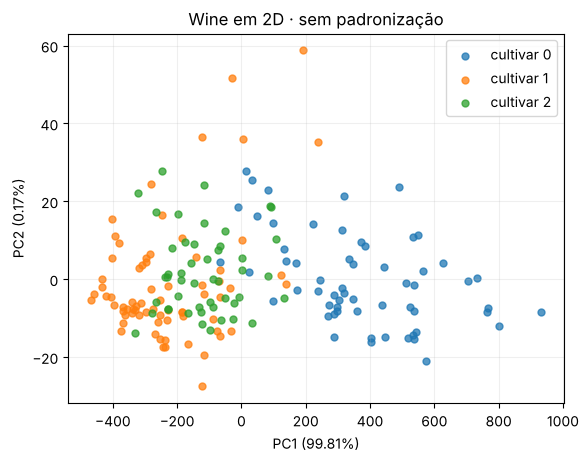

In [10]:
for c in range(3):
    plt.scatter(Z[y == c, 0], Z[y == c, 1], label=cultivares[c], alpha=0.75, s=25)
plt.xlabel(f"PC1 ({evr[0]*100:.2f}%)"); plt.ylabel(f"PC2 ({evr[1]*100:.2f}%)")
plt.title("Wine em 2D · sem padronização"); plt.legend(); plt.grid(alpha=0.2)
plt.show()

## Etapa 10 — Comparar com o scikit-learn

Os sinais dos componentes podem vir invertidos; por isso comparamos os **valores absolutos** e a reconstrução.

In [11]:
pca_sk = PCA(n_components=2).fit(X)
Z_sk = pca_sk.transform(X)

print("EVR manual: ", evr[:2].round(6))
print("EVR sklearn:", pca_sk.explained_variance_ratio_.round(6))
print("Mesmas projeções (a menos do sinal)?", np.allclose(np.abs(Z), np.abs(Z_sk)))
print("Mesma reconstrução?", np.allclose(Z @ W.T + media, pca_sk.inverse_transform(Z_sk)))

assert np.allclose(evr[:2], pca_sk.explained_variance_ratio_)
assert np.allclose(np.abs(Z), np.abs(Z_sk))

EVR manual:  [0.9981 0.0017]
EVR sklearn: [0.9981 0.0017]
Mesmas projeções (a menos do sinal)? True
Mesma reconstrução? True


## Etapa 11 — Padronizado × não padronizado

Repetimos o PCA manual com cada coluna padronizada (média 0, desvio 1). Agora todas as características pesam igual.

PC1 + PC2 sem padronização: 99.98%
PC1 + PC2 com padronização: 55.41%
Confere com StandardScaler + PCA do sklearn? True
PC1 padronizado — maiores pesos: flavanoids (-0.423), total_phenols (-0.395), od280/od315_of_diluted_wines (-0.376)
PC2 padronizado — maiores pesos: color_intensity (-0.530), alcohol (-0.484), proline (-0.365)


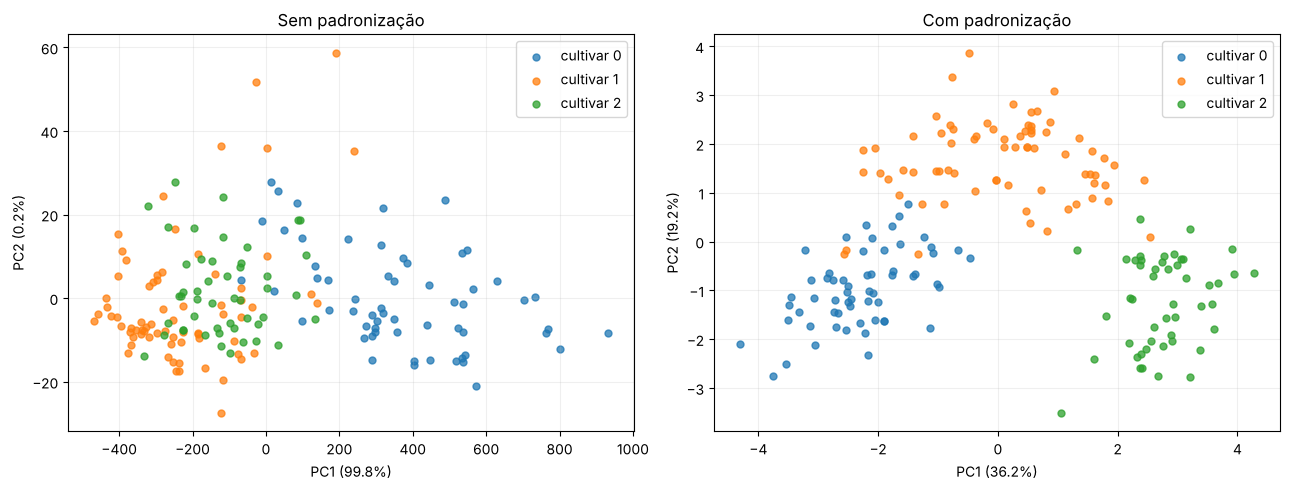

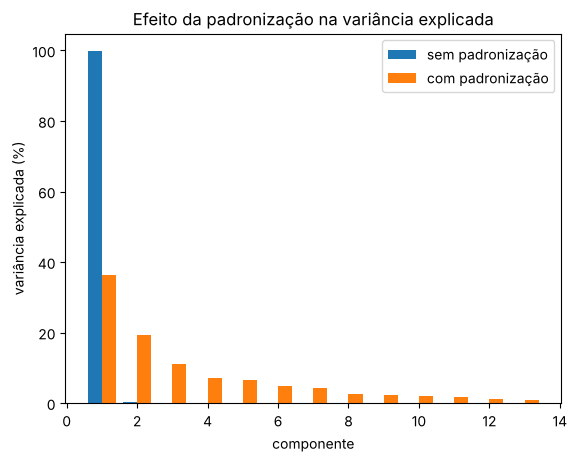

In [12]:
def pca_manual(X, k=2):
    media = X.mean(axis=0)
    Xc = X - media
    vals, vecs = np.linalg.eigh(Xc.T @ Xc / (len(X) - 1))
    ordem = np.argsort(vals)[::-1]
    vals, vecs = vals[ordem], vecs[:, ordem]
    return Xc @ vecs[:, :k], vals / vals.sum(), vecs[:, :k]

X_pad = (X - X.mean(axis=0)) / X.std(axis=0)
Z_pad, evr_pad, W_pad = pca_manual(X_pad)

print(f"PC1 + PC2 sem padronização: {evr[:2].sum()*100:.2f}%")
print(f"PC1 + PC2 com padronização: {evr_pad[:2].sum()*100:.2f}%")
print("Confere com StandardScaler + PCA do sklearn?",
      np.allclose(evr_pad[:2], PCA(2).fit(StandardScaler().fit_transform(X)).explained_variance_ratio_))

for pc in range(2):
    maiores = np.argsort(np.abs(W_pad[:, pc]))[::-1][:3]
    print(f"PC{pc+1} padronizado — maiores pesos:",
          ", ".join(f"{nomes[j]} ({W_pad[j, pc]:+.3f})" for j in maiores))

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for ax, Zp, e, titulo in [(eixos[0], Z, evr, "Sem padronização"),
                          (eixos[1], Z_pad, evr_pad, "Com padronização")]:
    for c in range(3):
        ax.scatter(Zp[y == c, 0], Zp[y == c, 1], label=cultivares[c], alpha=0.75, s=25)
    ax.set(xlabel=f"PC1 ({e[0]*100:.1f}%)", ylabel=f"PC2 ({e[1]*100:.1f}%)", title=titulo)
    ax.grid(alpha=0.2); ax.legend()
plt.tight_layout(); plt.show()

plt.bar(np.arange(1, 14) - 0.2, evr * 100, width=0.4, label="sem padronização")
plt.bar(np.arange(1, 14) + 0.2, evr_pad * 100, width=0.4, label="com padronização")
plt.xlabel("componente"); plt.ylabel("variância explicada (%)")
plt.title("Efeito da padronização na variância explicada"); plt.legend(); plt.show()

## Etapa 12 — Separação dos cultivares no 2D

Uma forma simples de medir se os grupos ficaram separados no plano: classificar cada vinho pelo **centro do cultivar mais próximo** em PC1 × PC2 e contar os acertos. (É só uma medida de separação visual, não um modelo avaliado em teste.)

In [13]:
def acerto_centro_mais_proximo(Z, y):
    centros = np.array([Z[y == c].mean(axis=0) for c in range(3)])
    d = ((Z[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2)
    return np.mean(d.argmin(axis=1) == y)

print(f"Separação no 2D sem padronização: {acerto_centro_mais_proximo(Z, y)*100:.1f}%")
print(f"Separação no 2D com padronização: {acerto_centro_mais_proximo(Z_pad, y)*100:.1f}%")

Separação no 2D sem padronização: 72.5%
Separação no 2D com padronização: 97.2%


## Interpretação

**Sem padronização**, o PCA parece excelente: PC1 + PC2 guardam **99,98%** da variância. Mas isso é ilusão de escala. A variância de `proline` (na casa de 100 000) é muito maior que a de todas as outras colunas juntas, então PC1 praticamente **é** a coluna `proline` (peso ≈ 1,00). No gráfico, os cultivares 1 e 2 ficam misturados, porque a projeção quase só enxerga uma característica.

**Com padronização**, cada característica passa a ter variância 1 e todas competem em pé de igualdade. PC1 + PC2 explicam menos (**55,41%**), mas os componentes agora combinam várias medidas químicas (flavonoides, fenóis totais, OD280/OD315 no PC1; intensidade de cor e álcool no PC2), e **os três cultivares aparecem bem separados**: classificando cada vinho pelo centro de cultivar mais próximo no plano, o acerto sobe de **72,5%** (sem padronização) para **97,2%** (com padronização).

**Conclusão:** variância explicada alta não garante uma projeção útil. Quando as características têm unidades e escalas diferentes, como aqui, é preciso padronizar antes do PCA. Os rótulos não foram usados em nenhum cálculo do PCA, só para colorir os gráficos e medir a separação no final.